findfont: Failed to find font weight bold for SimHei, now using 400.


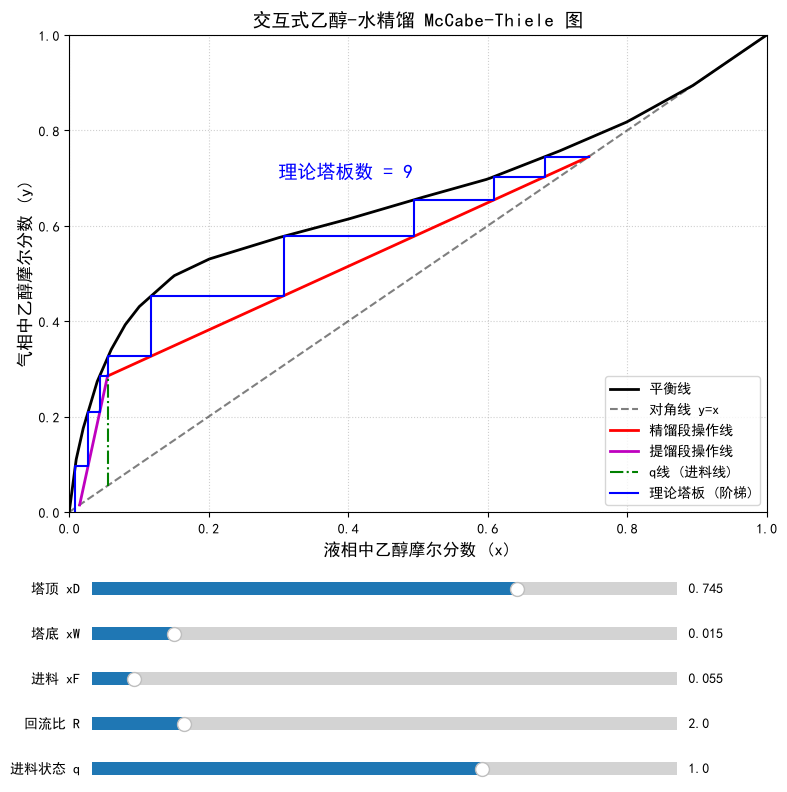

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.widgets import Slider
from scipy.interpolate import interp1d


# 设定中文字体
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# ================= 1. 真实乙醇-水相平衡数据 =================
x_data = np.array([0, 0.01, 0.02, 0.04, 0.06, 0.08, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.894, 1.0])
y_data = np.array([0, 0.11, 0.175, 0.273, 0.34, 0.392, 0.43, 0.495, 0.53, 0.575, 0.614, 0.657, 0.698, 0.755, 0.818, 0.894, 1.0])

f_y2x = interp1d(y_data, x_data, kind='linear', fill_value="extrapolate")
f_x2y = interp1d(x_data, y_data, kind='linear', fill_value="extrapolate")

x_curve = np.linspace(0, 1, 200)
y_curve = f_x2y(x_curve)

# ================= 2. 初始化图形窗口 =================
# 留出底部空间给滑块
fig, ax = plt.subplots(figsize=(9, 9))
plt.subplots_adjust(bottom=0.35) 

# 初始参数（使用你之前算出的部分回流数据）
init_xD = 0.744
init_xW = 0.015
init_xF = 0.056
init_R = 2.0
init_q = 1.0  # 进料热状态，1为泡点进料

# 静态线：平衡线与对角线
ax.plot(x_curve, y_curve, 'k-', linewidth=2, label='平衡线')
ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, label='对角线 y=x')

# 动态线对象（初始化，稍后通过 update 更新数据）
line_rect, = ax.plot([], [], 'r-', linewidth=2, label='精馏段操作线')
line_strip, = ax.plot([], [], 'm-', linewidth=2, label='提馏段操作线')
line_q, = ax.plot([], [], 'g-.', linewidth=1.5, label='q线 (进料线)')
line_steps, = ax.plot([], [], 'b-', linewidth=1.5, label='理论塔板 (阶梯)')
text_stage = ax.text(0.3, 0.7, '', fontsize=14, color='blue', fontweight='bold')

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel('液相中乙醇摩尔分数 (x)', fontsize=12)
ax.set_ylabel('气相中乙醇摩尔分数 (y)', fontsize=12)
ax.set_title('交互式乙醇-水精馏 McCabe-Thiele 图', fontsize=14)
ax.legend(loc='lower right')
ax.grid(True, linestyle=':', alpha=0.6)

# ================= 3. 核心更新函数 =================
def update(val):
    # 获取当前滑块的值
    xD = s_xD.val
    xW = s_xW.val
    xF = s_xF.val
    R = s_R.val
    q = s_q.val

    # 数据合法性检查
    if xD <= xF or xF <= xW:
        text_stage.set_text("参数错误: 必须满足 xD > xF > xW")
        line_rect.set_data([], [])
        line_strip.set_data([], [])
        line_q.set_data([], [])
        line_steps.set_data([], [])
        fig.canvas.draw_idle()
        return

    # --- 计算操作线 ---
    # 1. 精馏段
    slope_rect = R / (R + 1)
    intercept_rect = xD / (R + 1)
    x_rect_plot = np.linspace(xF, xD, 10)
    y_rect_plot = slope_rect * x_rect_plot + intercept_rect
    line_rect.set_data(x_rect_plot, y_rect_plot)

    # 2. q 线和交点
    if q == 1.0:
        x_q = xF
        y_q = slope_rect * x_q + intercept_rect
        x_q_plot = [xF, xF]
        y_q_plot = [xF, y_q]
    else:
        # 通用 q 线方程：y = (q/(q-1))x - (xF/(q-1))
        slope_q = q / (q - 1)
        intercept_q = -xF / (q - 1)
        x_q = (intercept_rect - intercept_q) / (slope_q - slope_rect)
        y_q = slope_rect * x_q + intercept_rect
        x_q_plot = np.linspace(xF, x_q, 10)
        y_q_plot = slope_q * x_q_plot + intercept_q
    
    line_q.set_data(x_q_plot, y_q_plot)

    # 3. 提馏段
    if x_q == xW:
        slope_strip = 0
    else:
        slope_strip = (y_q - xW) / (x_q - xW)
    intercept_strip = xW - slope_strip * xW
    x_strip_plot = np.linspace(xW, x_q, 10)
    y_strip_plot = slope_strip * x_strip_plot + intercept_strip
    line_strip.set_data(x_strip_plot, y_strip_plot)

    # --- 画阶梯 ---
    x_curr = xD
    y_curr = xD
    stage = 0
    x_steps = [x_curr]
    y_steps = [y_curr]

    while x_curr > xW:
        stage += 1
        
        # 横向到平衡线
        x_eq = f_y2x(y_curr)
        x_steps.append(x_eq)
        y_steps.append(y_curr)
        
        # 纵向到操作线
        if x_eq > x_q: # 跨过进料点
            y_next = slope_rect * x_eq + intercept_rect
        else:
            y_next = slope_strip * x_eq + intercept_strip
            
        x_steps.append(x_eq)
        y_steps.append(y_next)
        
        x_curr = x_eq
        y_curr = y_next

        # 防止死循环
        if stage > 200:
            text_stage.set_text("警告: 塔板数 > 200 (操作线接近平衡线)")
            break
    else:
        text_stage.set_text(f'理论塔板数 = {stage}')

    # 更新阶梯线
    line_steps.set_data(x_steps, y_steps)
    
    # 实时重绘
    fig.canvas.draw_idle()

# ================= 4. 添加滑块 =================
# 滑块位置：[左侧起始, 底部起始, 宽度, 高度]
ax_xD = plt.axes([0.15, 0.25, 0.65, 0.03])
ax_xW = plt.axes([0.15, 0.20, 0.65, 0.03])
ax_xF = plt.axes([0.15, 0.15, 0.65, 0.03])
ax_R  = plt.axes([0.15, 0.10, 0.65, 0.03])
ax_q  = plt.axes([0.15, 0.05, 0.65, 0.03])

s_xD = Slider(ax_xD, '塔顶 xD', 0.2, 0.95, valinit=init_xD, valstep=0.005)
s_xW = Slider(ax_xW, '塔底 xW', 0.001, 0.1, valinit=init_xW, valstep=0.001)
s_xF = Slider(ax_xF, '进料 xF', 0.02, 0.5, valinit=init_xF, valstep=0.005)
s_R  = Slider(ax_R, '回流比 R', 0.5, 10.0, valinit=init_R, valstep=0.1)
s_q  = Slider(ax_q, '进料状态 q', 0.0, 1.5, valinit=init_q, valstep=0.1)

# 绑定滑块事件
s_xD.on_changed(update)
s_xW.on_changed(update)
s_xF.on_changed(update)
s_R.on_changed(update)
s_q.on_changed(update)

# 初始触发一次绘图
update(None)

plt.show()